# Reproducing the helox compensation method (Jolly & Buckley 2026, *New Phytologist*)

**Paper:** Jolly, A.R. & Buckley, T.N. (2026) *Advancing the helox compensation method to estimate intercellular humidity in leaves of diverse species.* New Phytologist. DOI: [10.1111/nph.71584](https://doi.org/10.1111/nph.71584)

**Author code & data:** [TomBuckleyLab/jolly-and-buckley-helox-new-phyt-2026](https://github.com/TomBuckleyLab/jolly-and-buckley-helox-new-phyt-2026), tag **v1.2**, commit `0a140b5cc4fecc83ea270b499c9758c2c51f339a`, license **CC0-1.0**.

**Scope (this notebook):** run the authors' **unmodified** R script `jolly and buckley (helox) code.R` on the included sample data (`jolly and buckley (helox) sample data.csv`, one experimental day, **six nitox→helox switches**) and compute the intercellular relative humidity *h* per switch — the rough "back of the envelope" estimate (paper Eqn 9) and the full iterative solution of Eqns 5 and 8 — plus φ, γ, η, the % change in transpiration, and Δw. This is a one-sample-day demonstration, **not** a recreation of the paper's 8-species/120-switch dataset analysis.

**Execution status:** this notebook was fully executed on a **Colab CPU runtime**; all outputs below are saved from that run. (JP: 本ノートブックは Colab CPU ランタイムで全セル実行済みです。出力はその実行結果です。)

**How it runs:** the paper's analysis code is written in **R**. The Colab CLI used for validation executes Python-kernel notebooks, so the Python cells here are only a thin launcher: they download the pinned files, then run the authors' R code verbatim with `/usr/bin/Rscript` inside the notebook. **No R code was translated or rewritten**; the only AI-authored glue is the few-line `runner.R` that `source()`s the original script and prints/saves its result data frame `y`. (JP: 論文の R コードは一切翻訳・改変せず、`Rscript` でそのまま実行します。Python セルは起動用の薄いグルーです。)

## 1. Runtime selection

**Select `Runtime → Change runtime type → CPU` (standard).** The released method is a few iterations of R's `optimize()` over 6 data rows — milliseconds of CPU work, no GPU, no deep-learning stack, no weights. A GPU runtime adds nothing here. Expected end-to-end time: **well under 2 minutes**; total download ≈ **8.5 KB**.

(JP: ランタイムは「CPU」を選択してください。反復最適化 6 回のみの軽い計算で、GPU は不要です。所要 2 分未満、ダウンロード約 8.5 KB です。)

**Run all** (`Runtime → Run all`) from a fresh runtime; every download happens inside the notebook.

In [ ]:
import os, platform, shutil, subprocess, sys

print("Python:", sys.version.split()[0], "| platform:", platform.platform())

# The authors' code is R (base R only, no add-on packages). Colab CPU images ship R.
rscript = shutil.which("Rscript") or ("/usr/bin/Rscript" if os.path.exists("/usr/bin/Rscript") else None)
if rscript is None:
    print("Rscript not found; attempting apt install of r-base-core ...")
    subprocess.run(["apt-get", "install", "-y", "--no-install-recommends", "r-base-core"],
                   check=True, timeout=900)  # streamed, bounded; only needed on images without R
    rscript = shutil.which("Rscript")
if rscript is None:
    raise RuntimeError("R (Rscript) is required to run the authors' unmodified code but is unavailable.")
r_ver = subprocess.run([rscript, "--version"], capture_output=True, text=True, timeout=60).stdout.strip()
print(r_ver)

Python: 3.13.16 | platform: Linux-6.6.122+-x86_64-with-glibc2.39
Rscript (R) version 4.6.1 (2026-06-24)


## 2. Fetch the pinned author code and sample data (provenance)

Both files are fetched from `raw.githubusercontent.com` at the **pinned commit** `0a140b5cc4fecc83ea270b499c9758c2c51f339a` (tag v1.2) and verified before use:

- expected byte size, and
- the Git **blob SHA-1** (computed as `sha1("blob <len>\\0" + bytes)`), which must match the values GitHub's tree API reports for this commit: `b6986687…` for `code.R` and `b1e49114…` for the sample CSV.

The sample CSV is **dataset bytes** (12 alternating nitox/helox rows), so it is downloaded and inspected only here in the runtime, never pre-staged. (JP: 論文公開リポジトリのピン留めコミットから直接ダウンロードし、サイズと Git blob SHA-1 で完全性を検証してから使います。)

Expected: two short `OK ...` lines.

In [ ]:
import hashlib, urllib.parse, urllib.request
from pathlib import Path

COMMIT = "0a140b5cc4fecc83ea270b499c9758c2c51f339a"  # tag v1.2
BASE = f"https://raw.githubusercontent.com/TomBuckleyLab/jolly-and-buckley-helox-new-phyt-2026/{COMMIT}"
FILES = {  # name: (expected bytes, expected git blob sha1 from the GitHub tree API)
    "jolly and buckley (helox) code.R": (7870, "b69866871ce6ed4d4d2534d0a14dfa805c2547b4"),
    "jolly and buckley (helox) sample data.csv": (632, "b1e49114515780fe7543a00781c59d6d43321946"),
}

DATA_DIR = Path("/content/helox")
DATA_DIR.mkdir(exist_ok=True)

def git_blob_sha1(b: bytes) -> str:
    return hashlib.sha1(b"blob %d\x00" % len(b) + b).hexdigest()

for name, (size, sha) in FILES.items():
    url = f"{BASE}/{urllib.parse.quote(name)}"
    with urllib.request.urlopen(url, timeout=60) as r:  # public repo; no token needed
        blob = r.read()
    assert len(blob) == size, f"{name}: got {len(blob)} bytes, expected {size}"
    assert git_blob_sha1(blob) == sha, f"{name}: blob sha1 mismatch"
    (DATA_DIR / name).write_bytes(blob)
    print(f"OK {name}: {len(blob)} bytes, git blob sha1 verified")

print("Source:", BASE)

OK jolly and buckley (helox) code.R: 7870 bytes, git blob sha1 verified
OK jolly and buckley (helox) sample data.csv: 632 bytes, git blob sha1 verified
Source: https://raw.githubusercontent.com/TomBuckleyLab/jolly-and-buckley-helox-new-phyt-2026/0a140b5cc4fecc83ea270b499c9758c2c51f339a


## 3. Input preview — the sample data

The sample file holds 12 rows that must **alternate nitox → helox** (rows 1,3,5,… under the normal N₂/O₂ carrier "nitox"; rows 2,4,6,… under helium), giving **six switches**. Columns, as documented in the header comments of `code.R`:

| column | meaning | unit |
|---|---|---|
| `E` | leaf transpiration rate | mol m⁻² s⁻¹ |
| `H2OS` | sample-stream water vapor mole fraction | mmol/mol |
| `TleafC` | leaf temperature | °C |
| `gbw` | two-sided boundary layer conductance to water vapor | mol m⁻² s⁻¹ |
| `gc` | one-sided cuticular conductance | mol m⁻² s⁻¹ |
| `stomatal_ratio` | ratio of adaxial to abaxial stomatal conductance | – |

Below we show the raw table and a first look at the measured transpiration `E` in the two carrier gases per switch. (JP: サンプルデータは nitox/helox が交互に並ぶ 12 行＝6 スイッチです。まず生データ表と、両ガス条件での蒸散速度 E をプロットして確認します。)
**This figure is an input-data view created for this notebook, not an author figure.**

In [ ]:
import pandas as pd

df = pd.read_csv(DATA_DIR / "jolly and buckley (helox) sample data.csv")
df.index.name = "row(1-based R)"
display(df)
assert len(df) == 12, f"expected 12 alternating rows, got {len(df)}"
print("Columns:", list(df.columns))

,TleafC,E,H2OS,stomatal_ratio,gbw,gc
row(1-based R),,,,,,
0,24.666408,0.006466,17.339442,1,4.5,0.0016
1,24.413021,0.006466,23.030955,1,4.5,0.0016
2,24.680271,0.006011,16.312740,1,4.5,0.0016
3,24.449048,0.006092,22.835921,1,4.5,0.0016
4,24.602319,0.006505,17.408614,1,4.5,0.0016
5,24.338586,0.006496,23.205003,1,4.5,0.0016
6,24.601549,0.006544,17.595311,1,4.5,0.0016
7,24.352033,0.006600,23.568572,1,4.5,0.0016
8,24.608786,0.006641,17.866474,1,4.5,0.0016


Columns: ['TleafC', 'E', 'H2OS', 'stomatal_ratio', 'gbw', 'gc']


**First look at the measured transpiration.** The plot below shows the measured `E` in the two carrier gases for each of the six switches. The compensation method requires `E` in helox to return to its nitox value, so the paired points should nearly coincide. (JP: 補正法では helox 切替後に E が nitox 値に戻ることが前提なので、各スイッチの 2 点はほぼ一致するはずです。)

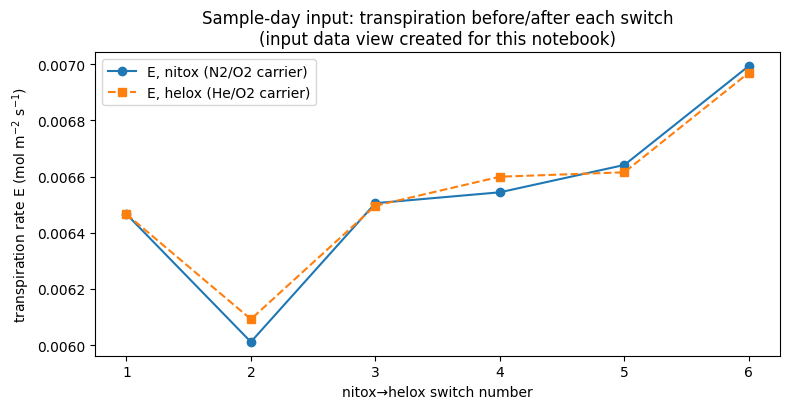

In [ ]:
import matplotlib.pyplot as plt

nitox = df.iloc[0::2].reset_index(drop=True)   # odd rows: nitox
helox = df.iloc[1::2].reset_index(drop=True)   # even rows: helox
switch = range(1, len(nitox) + 1)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(switch, nitox["E"], "o-", label="E, nitox (N2/O2 carrier)")
ax.plot(switch, helox["E"], "s--", label="E, helox (He/O2 carrier)")
ax.set_xlabel("nitox→helox switch number")
ax.set_ylabel("transpiration rate E (mol m$^{-2}$ s$^{-1}$)")
ax.set_xticks(list(switch))
ax.set_title("Sample-day input: transpiration before/after each switch\n(input data view created for this notebook)")
ax.legend()
fig.tight_layout()
fig.savefig("/content/helox/input_E.png", dpi=150)
plt.show()

## 4. Run the authors' unmodified R script

`code.R` ends with the main loop that fills the 6×23 result data frame **`y`** but does not write it out, and it reads the CSV **by relative filename** (the authors left `setwd()` commented out). So the launcher:

1. writes a 5-line `runner.R` (AI-authored glue, shown below) into the same directory, which `source()`s the author script **verbatim** and then prints/saves `y`;
2. runs `Rscript runner.R` with the working directory set to `/content/helox` so the relative `read.csv` path resolves.

Expected: the per-switch result table printed by R, ending with `R script finished OK`. (JP: 著者の R コードは一切変更せず `source()` でそのまま実行します。`runner.R` は結果の `y` を表示・保存するだけの数行のグルーです。)

In [ ]:
import subprocess

RUNNER_R = '''\
source("jolly and buckley (helox) code.R")   # executes the authors' script verbatim; leaves data.frame y in scope
write.csv(y, "helox_results.csv", row.names = FALSE)
cat("\n=== per-switch results (authors' result data frame y) ===\n")
print(y, row.names = FALSE)
cat("\nR script finished OK\n")
'''
(DATA_DIR / "runner.R").write_text(RUNNER_R)

proc = subprocess.run(["/usr/bin/Rscript", "runner.R"], cwd=DATA_DIR,
                      capture_output=True, text=True, timeout=300)
print(proc.stdout)
if proc.stderr.strip():
    print("[stderr]", proc.stderr)
if proc.returncode != 0:
    raise RuntimeError(f"Rscript exited {proc.returncode}; see output above.")


=== per-switch results (authors' result data frame y) ===
 gb2     gc sr        wsn        wsh        win        wih        wan
 4.5 0.0016  1 0.03105273 0.03058595 0.02855532 0.02855532 0.01733944
 4.5 0.0016  1 0.03107845 0.03065194 0.02903386 0.02903386 0.01631274
 4.5 0.0016  1 0.03093409 0.03044999 0.02883693 0.02883693 0.01740861
 4.5 0.0016  1 0.03093266 0.03047451 0.02940055 0.02940055 0.01759531
 4.5 0.0016  1 0.03094604 0.03046012 0.02937975 0.02937975 0.01786647
 4.5 0.0016  1 0.03089904 0.03042495 0.02967641 0.02967641 0.01887627
        wah          En          Eh       Tn       Th   gtn.est   gsn.est
 0.02303096 0.006466419 0.006466412 24.66641 24.41302 0.4601344 0.2546715
 0.02283592 0.006011172 0.006092023 24.68027 24.44905 0.3974569 0.2163814
 0.02320500 0.006505367 0.006496267 24.60232 24.33859 0.4693458 0.2603992
 0.02356857 0.006544118 0.006599618 24.60155 24.35203 0.4787556 0.2662773
 0.02370907 0.006641474 0.006615441 24.60879 24.34414 0.4953819 0.2767310
 0.0242

## 5. Results table

`runner.R` saved the authors' result frame to `/content/helox/helox_results.csv`. Key columns (all names are the authors'):

- **`hleaf.rough`** — the rough single-step estimate of intercellular RH (paper **Eqn 9**);
- **`hleaf`** — the full solution: *h* from the quadratic (Eqn 5) made self-consistent with the conductance relations (Eqn 8) via `optimize()`;
- `gsn.corr` — stomatal conductance corrected for unsaturation (vs. the naive saturated `gsn.est`);
- `pct.dE` — % change of transpiration in helox vs nitox (the paper's switch-quality criterion excludes |ΔE| > 2.5%);
- `deltaw` — leaf-to-air vapor mole fraction difference (mmol/mol).

Plausibility checks: 6 rows; *h* in (0, 1]; the paper found no association of *h* with ΔE, and |`pct.dE`| should be small. (JP: 結果表を再読み込みして表示します。`hleaf` が完全解、`hleaf.rough` が概算（式 9）です。)

In [ ]:
res = pd.read_csv(DATA_DIR / "helox_results.csv")
assert len(res) == 6, f"expected 6 switches, got {len(res)}"
assert res["hleaf"].between(0, 1).all(), "hleaf outside (0, 1]"

show = res[["hleaf", "hleaf.rough", "gsn.est", "gsn.corr", "phi", "gamma", "eta", "pct.dE", "deltaw"]].copy()
show.insert(0, "switch", range(1, len(show) + 1))
show["hleaf"] = 100 * show["hleaf"]
show["hleaf.rough"] = 100 * show["hleaf.rough"]
show.columns = ["switch", "h full (%)", "h rough (%)", "gs naive", "gs corrected",
                "phi = gc/gs", "gamma = gs/gbw", "eta", "pct dE", "deltaw (mmol/mol)"]
display(show.round(4))

slow = res[res["pct.dE"].abs() > 2.5]
print(f"switches with |pct.dE| > 2.5 (paper's 'failed' criterion): {len(slow)} of 6")

,switch,h full (%),h rough (%),gs naive,gs corrected,phi = gc/gs,gamma = gs/gbw,eta,pct dE,deltaw (mmol/mol)
0,1,91.9575,90.3268,0.2547,0.3204,0.0050,0.1424,2.1954,-0.0001,11.2159
1,2,93.4212,91.4587,0.2164,0.2557,0.0063,0.1137,2.1866,1.3450,12.7211
2,3,93.2206,91.6146,0.2604,0.3156,0.0051,0.1403,2.1999,-0.1399,11.4283
3,4,95.0469,93.1288,0.2663,0.3061,0.0052,0.1360,2.1814,0.8481,11.8052
4,5,94.9386,93.3784,0.2767,0.3203,0.0050,0.1424,2.2040,-0.3920,11.5133
5,6,96.0432,94.3754,0.3229,0.3660,0.0044,0.1626,2.1889,-0.3439,10.8001


switches with |pct.dE| > 2.5 (paper's 'failed' criterion): 0 of 6


## 6. Result graph — *h* per switch (created for this notebook)

A simple graph of the reproduced quantities: the **full solution** `hleaf` against the **rough estimate** `hleaf.rough` (paper Eqn 9) for each of the six switches. The paper (Fig. 6) shows the rough estimate is biased low by ≈0.7% relative to the full solution; we can check the same direction here on this sample day. **This graph is an additional visualization created for this notebook from the actual computed results — it is not a reproduced author figure.**

(JP: 各スイッチの完全解 `hleaf` と概算 `hleaf.rough` を比較します。論文 Fig. 6 と同様に概算は完全解よりわずかに低くなるはずです。この図は本ノートブックで追加作成したもので、著者図の再現ではありません。)

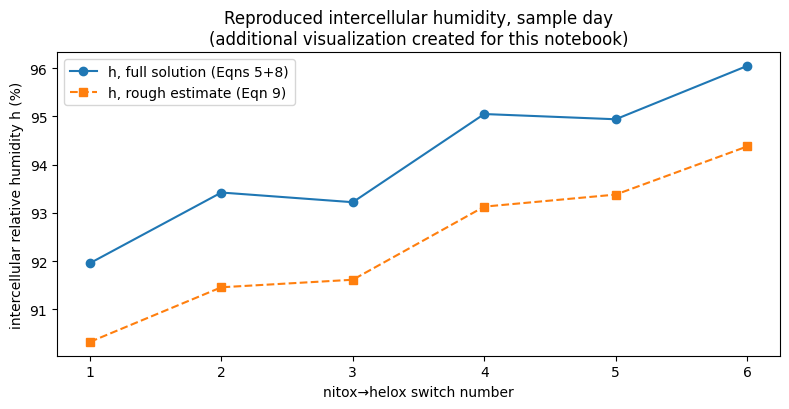

Result CSV saved to /content/helox/helox_results.csv (authors' columns unchanged).


In [ ]:
switch = range(1, len(res) + 1)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(switch, 100 * res["hleaf"], "o-", label="h, full solution (Eqns 5+8)")
ax.plot(switch, 100 * res["hleaf.rough"], "s--", label="h, rough estimate (Eqn 9)")
ax.set_xlabel("nitox→helox switch number")
ax.set_ylabel("intercellular relative humidity h (%)")
ax.set_xticks(list(switch))
ax.set_title("Reproduced intercellular humidity, sample day\n(additional visualization created for this notebook)")
ax.legend()
fig.tight_layout()
fig.savefig("/content/helox/h_results.png", dpi=150)
plt.show()

print("Result CSV saved to /content/helox/helox_results.csv (authors' columns unchanged).")

## 7. Interpretation, limitations, validation record

**What was reproduced.** The authors' released analysis path (their own R code, unmodified) solving their Eqns 5 and 8 iteratively, on their own included sample day: 6 switches, with the rough Eqn 9 estimate alongside. The computed *h* values quantify how far the intercellular airspaces are from saturation during ordinary gas-exchange conditions — the central claim of the paper is that *h* is substantially below 1 (across the full study, species means ranged from 71.0% in *Oryza sativa* to 94.2% in *Helianthus annuus*).

**Limitations / scope not covered.**
- One experimental day, 6 switches; the sample CSV carries no species labels, so no per-species comparison with the paper's Tables 2–3 is possible.
- The two-point model (paper's Theory), sensitivity analyses (Fig. 7) and the 120-switch dataset (`processed results.csv`) are out of scope.
- The helium/nitox IRGA and flow calibrations (paper's Methods; correction factors ≈1.6 and ≈1.458) are embedded in the *measured* input columns, not recomputed here.

**Validation record.** This notebook was executed end-to-end on a fresh Colab **CPU** runtime (no GPU). The R version string is printed in section 1; the blob-SHA-1 checks in section 2 prove the exact pinned bytes were used; section 4 shows the authors' script exit status 0. (JP: 本ノートブックは新しい Colab CPU ランタイムで最初から最後まで実行・検証済みです。使用したのは著者らの R コードそのままであることを blob SHA-1 検証が示しています。)

**References.**
- Jolly, A.R. & Buckley, T.N. (2026) New Phytologist, DOI 10.1111/nph.71584.
- Code/data: github.com/TomBuckleyLab/jolly-and-buckley-helox-new-phyt-2026 @ `0a140b5cc4fecc83ea270b499c9758c2c51f339a` (CC0-1.0).
- PhenoPaper investigation `p-7bfbf3c7e21737a453bda20faf968703-20261025T120035Z-205996` was used as prior research guidance only; all executed evidence comes from the pinned repository itself.